In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import nltk

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
import urllib.request
import zipfile
import os

url = "https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip"
zip_path = "sentiment_labelled_sentences.zip"

# Download the file
urllib.request.urlretrieve(url, zip_path)

# Extract the zip file
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(".")

print("Dataset downloaded and extracted successfully!")

Dataset downloaded and extracted successfully!


In [8]:
import os

for root, dirs, files in os.walk("sentiment_dataset"):
    for file in files:
        if file.endswith(".txt"):
            print(os.path.join(root, file))

In [10]:
import glob
import os

# Correct path and pattern for the extracted files
files = glob.glob("sentiment labelled sentences/*.txt")

dataframes = []

for file in files:
    # Skip readme.txt as it does not contain the dataset
    if "readme.txt" in file:
        continue
    df = pd.read_csv(file, sep="\t", header=None,
                     names=["Review", "Sentiment"])
    df["Source"] = os.path.basename(file)
    dataframes.append(df)

data = pd.concat(dataframes, ignore_index=True)

print("Dataset loaded successfully!")
print(data.head())
print("\nDataset shape:", data.shape)

Dataset loaded successfully!
                                              Review  Sentiment  \
0                           Wow... Loved this place.          1   
1                                 Crust is not good.          0   
2          Not tasty and the texture was just nasty.          0   
3  Stopped by during the late May bank holiday of...          1   
4  The selection on the menu was great and so wer...          1   

              Source  
0  yelp_labelled.txt  
1  yelp_labelled.txt  
2  yelp_labelled.txt  
3  yelp_labelled.txt  
4  yelp_labelled.txt  

Dataset shape: (2748, 3)


In [11]:
print("Total Reviews:", len(data))

print("\nMissing Values:")
print(data.isnull().sum())

print("\nSentiment Distribution:")
print(data["Sentiment"].value_counts())

print("\nDataset Information:")
print(data.info())

Total Reviews: 2748

Missing Values:
Review       0
Sentiment    0
Source       0
dtype: int64

Sentiment Distribution:
Sentiment
1    1386
0    1362
Name: count, dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2748 entries, 0 to 2747
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Review     2748 non-null   object
 1   Sentiment  2748 non-null   int64 
 2   Source     2748 non-null   object
dtypes: int64(1), object(2)
memory usage: 64.5+ KB
None


In [12]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

data["Cleaned_Review"] = data["Review"].apply(clean_text)

print("Text cleaning completed!")
print(data[["Review", "Cleaned_Review"]].head(10))

Text cleaning completed!
                                              Review  \
0                           Wow... Loved this place.   
1                                 Crust is not good.   
2          Not tasty and the texture was just nasty.   
3  Stopped by during the late May bank holiday of...   
4  The selection on the menu was great and so wer...   
5     Now I am getting angry and I want my damn pho.   
6              Honeslty it didn't taste THAT fresh.)   
7  The potatoes were like rubber and you could te...   
8                          The fries were great too.   
9                                     A great touch.   

                                      Cleaned_Review  
0                               wow loved this place  
1                                  crust is not good  
2           not tasty and the texture was just nasty  
3  stopped by during the late may bank holiday of...  
4  the selection on the menu was great and so wer...  
5      now i am getting angr

In [13]:
tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(data["Cleaned_Review"])

y = data["Sentiment"]

print("TF-IDF conversion completed!")
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

TF-IDF conversion completed!
Feature matrix shape: (2748, 5000)
Target shape: (2748,)


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data splitting completed!")
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Data splitting completed!
Training data: (2198, 5000)
Testing data: (550, 5000)


In [15]:
model = MultinomialNB()

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [16]:
y_pred = model.predict(X_test)

print("Predictions completed!")
print("\nFirst 10 Predictions:")
print(y_pred[:10])

print("\nActual Sentiments:")
print(y_test.iloc[:10].values)

Predictions completed!

First 10 Predictions:
[1 0 0 1 1 1 1 0 1 1]

Actual Sentiments:
[0 0 0 1 1 0 1 1 1 1]


In [17]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 81.81818181818183 %

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.83      0.82       273
           1       0.83      0.81      0.82       277

    accuracy                           0.82       550
   macro avg       0.82      0.82      0.82       550
weighted avg       0.82      0.82      0.82       550



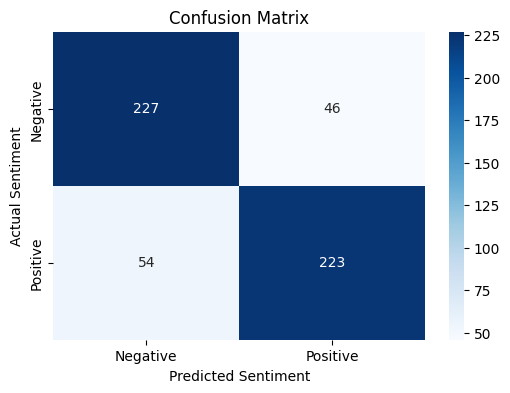

In [18]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"])

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Confusion Matrix")
plt.show()

In [19]:
new_reviews = [
    "The product is excellent and I love it",
    "Very bad quality and terrible experience",
    "Amazing product, highly recommended",
    "I am disappointed with this purchase"
]

cleaned_reviews = [clean_text(review) for review in new_reviews]

new_features = tfidf.transform(cleaned_reviews)

predictions = model.predict(new_features)

for review, sentiment in zip(new_reviews, predictions):
    print("Review:", review)
    print("Predicted Sentiment:",
          "Positive" if sentiment == 1 else "Negative")
    print("-" * 50)

Review: The product is excellent and I love it
Predicted Sentiment: Positive
--------------------------------------------------
Review: Very bad quality and terrible experience
Predicted Sentiment: Negative
--------------------------------------------------
Review: Amazing product, highly recommended
Predicted Sentiment: Positive
--------------------------------------------------
Review: I am disappointed with this purchase
Predicted Sentiment: Negative
--------------------------------------------------


In [20]:
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def advanced_clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    tokens = text.split()
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]
    return " ".join(tokens)

data["Processed_Review"] = data["Review"].apply(advanced_clean_text)

print("Advanced text preprocessing completed!")
print(data[["Review", "Processed_Review"]].head())

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Advanced text preprocessing completed!
                                              Review  \
0                           Wow... Loved this place.   
1                                 Crust is not good.   
2          Not tasty and the texture was just nasty.   
3  Stopped by during the late May bank holiday of...   
4  The selection on the menu was great and so wer...   

                                    Processed_Review  
0                                    wow loved place  
1                                         crust good  
2                                tasty texture nasty  
3  stopped late may bank holiday rick steve recom...  
4                         selection menu great price  


In [21]:
tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(data["Processed_Review"])
y = data["Sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Updated TF-IDF features successfully!")
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Updated TF-IDF features successfully!
Training shape: (2198, 4748)
Testing shape: (550, 4748)


In [22]:
model = MultinomialNB()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Updated model training completed!")
print("Model Accuracy:", accuracy_score(y_test, y_pred) * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Updated model training completed!
Model Accuracy: 80.0 %

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.76      0.79       273
           1       0.78      0.84      0.81       277

    accuracy                           0.80       550
   macro avg       0.80      0.80      0.80       550
weighted avg       0.80      0.80      0.80       550



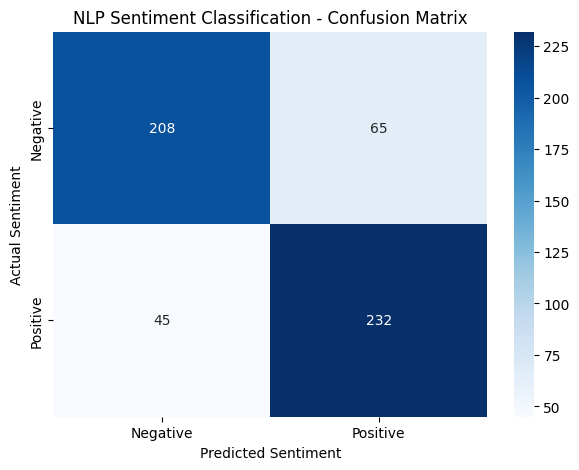

In [23]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("NLP Sentiment Classification - Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.show()

In [24]:
new_reviews = [
    "The product is excellent and I love it",
    "Very bad quality and terrible experience",
    "Amazing product, highly recommended",
    "I am disappointed with this purchase"
]

processed_reviews = [
    advanced_clean_text(review) for review in new_reviews
]

new_features = tfidf.transform(processed_reviews)

predictions = model.predict(new_features)

for review, sentiment in zip(new_reviews, predictions):
    print("Review:", review)
    print("Sentiment:", "Positive" if sentiment == 1 else "Negative")
    print("-" * 40)

Review: The product is excellent and I love it
Sentiment: Positive
----------------------------------------
Review: Very bad quality and terrible experience
Sentiment: Negative
----------------------------------------
Review: Amazing product, highly recommended
Sentiment: Positive
----------------------------------------
Review: I am disappointed with this purchase
Sentiment: Negative
----------------------------------------
